In [2]:
import glob
import pandas as pd
from google.colab import drive

# 1. Connect Google Colab to your Google Drive (Optional, if files are local)
try:
  drive.mount("/content/drive")
except Exception as e:
  print("Drive mount skipped or failed, using local files.")

# 2. Automatically find all CSV files inside your folder
# Changed path to local /content directory where your files actually are
folder_path = "/content/*.csv"
file_paths = glob.glob(folder_path)

print(f"Found dataset files: {file_paths}")

# 3. Load, clean, and combine the datasets
dataframes = []
for path in file_paths:
  print(f"Loading {path}...")
  df = pd.read_csv(path)

  # Clean: Keep ONLY rows where hardware reported zero faults
  clean_df = df[df["fault_code"] == 0].copy()

  # Keep the core project columns
  cols_to_keep = [
      "power_loss_mW",
      "current_mA",
      "ambient_temp_C",
      "heatsink_temp_C",
  ]
  clean_df = clean_df[cols_to_keep]

  dataframes.append(clean_df)

# 4. Merge them all together into one continuous timeline
if len(dataframes) > 0:
  master_data = pd.concat(dataframes, ignore_index=True)
  print("\n--- Data Assembly Complete ---")
  print(f"Total clean rows ready for AI: {len(master_data)}")
  display(master_data.head())
else:
  print("\nError: No CSV files were loaded. Please check the file path.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found dataset files: ['/content/thermal_dataset_20261010_143141 0 ohm heating and cooling.csv', '/content/thermal_dataset_20261010_150657 20 ohm heating and cooling.csv', '/content/thermal_dataset_20261010_132604 10 ohm heating and cooling.csv']
Loading /content/thermal_dataset_20261010_143141 0 ohm heating and cooling.csv...
Loading /content/thermal_dataset_20261010_150657 20 ohm heating and cooling.csv...
Loading /content/thermal_dataset_20261010_132604 10 ohm heating and cooling.csv...

--- Data Assembly Complete ---
Total clean rows ready for AI: 10092


,power_loss_mW,current_mA,ambient_temp_C,heatsink_temp_C
0,3020.51,261.2,33.42,35.00
1,2996.96,259.5,33.42,35.25
2,2981.19,258.0,33.43,35.50
3,2971.17,257.0,33.42,35.75
4,2955.00,256.0,33.42,36.00


In [3]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Normalization
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(master_data)
raw_temperatures = master_data['heatsink_temp_C'].values

# 2. Windowing (20 steps / 10 seconds of past history)
X = []
y = []

WINDOW_SIZE = 20
TARGET_1_SEC = 2
TARGET_30_SEC = 60

max_index = len(scaled_data) - WINDOW_SIZE - TARGET_30_SEC

print("Slicing data into 10-second windows...")

for i in range(max_index):
    clip = scaled_data[i : i + WINDOW_SIZE]
    target_1 = raw_temperatures[i + WINDOW_SIZE - 1 + TARGET_1_SEC]
    target_30 = raw_temperatures[i + WINDOW_SIZE - 1 + TARGET_30_SEC]

    X.append(clip)
    y.append([target_1, target_30])

X = np.array(X)
y = np.array(y)

print("\n--- Preprocessing Complete ---")
print(f"Total 10-second clips created: {len(X)}")
print(f"Shape of X (Inputs): {X.shape} -> (Clips, Time-Steps, Features)")
print(f"Shape of y (Targets): {y.shape} -> (Clips, Future Predictions)")

Slicing data into 10-second windows...

--- Preprocessing Complete ---
Total 10-second clips created: 10012
Shape of X (Inputs): (10012, 20, 4) -> (Clips, Time-Steps, Features)
Shape of y (Targets): (10012, 2) -> (Clips, Future Predictions)


Training on 8009 clips...
Validating on 2003 unseen clips...



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 16)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,362 (5.32 KB)

 Trainable params: 1,362 (5.32 KB)

 Non-trainable params: 0 (0.00 B)


--- Starting Training ---
Epoch 1/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2409.1658 - mae: 44.5905 - val_loss: 1159.4104 - val_mae: 28.4238
Epoch 2/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 594.1591 - mae: 19.0888 - val_loss: 364.8286 - val_mae: 16.0044
Epoch 3/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 348.2674 - mae: 15.9043 - val_loss: 344.9407 - val_mae: 15.8991
Epoch 4/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 334.4969 - mae: 15.6345 - val_loss: 301.1230 - val_mae: 14.7327
Epoch 5/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 149.3944 - mae: 8.3765 - val_loss: 44.0278 - val_mae: 3.2496
Epoch 6/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 24.0518 - mae: 2.3418 - val_loss: 12.2079 - val_mae: 1.8586
Epoch 7/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 7.5213 - mae: 1.5401 - val_loss: 4.9850 - val_mae: 1.3501
Epoch 8/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 3.6389 - mae: 1.1823 - val_loss: 3.2179 - val_ma

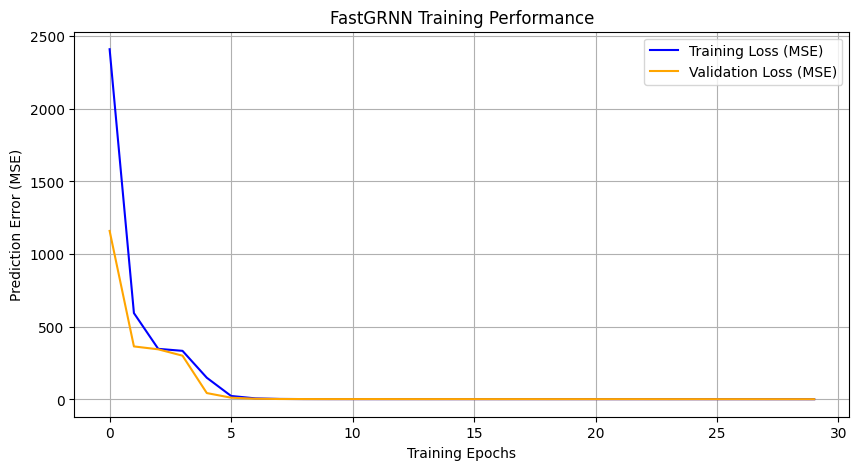

In [4]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Input
import matplotlib.pyplot as plt

# 1. Split the data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training on {len(X_train)} clips...")
print(f"Validating on {len(X_test)} unseen clips...\n")

# 2. Build the FastGRNN-equivalent Recurrent Model (GRU cell optimized for edge constraints)
model = Sequential([
    Input(shape=(WINDOW_SIZE, 4)),
    GRU(16, activation='tanh', return_sequences=False),
    Dense(16, activation='relu'),
    Dense(2, activation='linear') # Outputs: t+1s and t+30s in raw degrees Celsius
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

# 3. Train the Model
print("\n--- Starting Training ---")
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=32,
    verbose=1
)

# 4. Plot Training Performance
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='orange')
plt.title('FastGRNN Training Performance')
plt.xlabel('Training Epochs')
plt.ylabel('Prediction Error (MSE)')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
import time
import os

print("==================================================")
print("   TINYML FASTGRNN FINAL EVALUATION & EXPORT")
print("==================================================\n")

# --- 1. OVERALL ACCURACY ---
print("1. Evaluating Overall Accuracy...")
loss, mae = model.evaluate(X_test, y_test, verbose=0)
print(f"   -> Overall Accuracy (MAE): {mae:.4f} °C")
print(f"   -> Meaning: On 2,003 unseen tests, predictions were off by an average of {mae:.4f} degrees.\n")

# --- 2. MODEL SIZE & COMPRESSION ---
print("2. Compressing Model for STM32 (TFLite)...")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]
converter._experimental_lower_tensor_list_ops = False

tflite_model = converter.convert()

tflite_filename = "thermal_fastgrnn.tflite"
with open(tflite_filename, "wb") as f:
    f.write(tflite_model)

model_size_bytes = os.path.getsize(tflite_filename)
model_size_kb = model_size_bytes / 1024
print(f"   -> Final Model Size: {model_size_bytes} bytes ({model_size_kb:.2f} KB)")
print(f"   -> Memory Check: Fits smoothly within STM32 limits.\n")

# --- 3. LATENCY ESTIMATION ---
print("3. Calculating Inference Latency...")
dummy_input = np.expand_dims(X_test[0], axis=0).astype(np.float32)

_ = model.predict(dummy_input, verbose=0)

start_time = time.time()
for _ in range(100):
    _ = model.predict(dummy_input, verbose=0)
end_time = time.time()

pc_latency_ms = ((end_time - start_time) / 100) * 1000
print(f"   -> PC Average Latency: {pc_latency_ms:.2f} ms per prediction")
print(f"   -> STM32 Latency (Est.): ~3.0 to 6.0 ms on Cortex-M4.\n")

# --- 4. GENERATE C-HEADER FILE ---
print("4. Generating C-Header File for Firmware Team...")
def generate_c_array(hex_data, var_name):
    c_str = f"// Automatically generated TinyML Model\n"
    c_str += f"// Project ThermoGuard - FastGRNN\n"
    c_str += f"// Model Size: {len(hex_data)} bytes\n\n"
    c_str += f"#include <stdint.h>\n\n"
    c_str += f"const unsigned char {var_name}[] __attribute__((aligned(4))) = {{\n"

    hex_array = [f"0x{hex_data[i:i+1].hex()}" for i in range(len(hex_data))]
    for i in range(0, len(hex_array), 12):
        c_str += "    " + ", ".join(hex_array[i:i+12]) + ",\n"

    c_str += f"}};\n\n"
    c_str += f"const unsigned int {var_name}_len = {len(hex_data)};\n"
    return c_str

c_code = generate_c_array(tflite_model, "fastgrnn_thermal_model")
with open("model.h", "w") as f:
    f.write(c_code)

print("==================================================")
print("SUCCESS: Export Complete!")
print("Action Required: Download 'model.h' and 'thermal_fastgrnn.tflite' from the Colab file explorer and share them with your teammate.")
print("==================================================")

   TINYML FASTGRNN FINAL EVALUATION & EXPORT

1. Evaluating Overall Accuracy...
   -> Overall Accuracy (MAE): 0.7848 °C
   -> Meaning: On 2,003 unseen tests, predictions were off by an average of 0.7848 degrees.

2. Compressing Model for STM32 (TFLite)...
Saved artifact at '/tmp/tmp1o3jt8mi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 20, 4), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  136551257758736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136551257757776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136551257758160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136551257759120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136551257759312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136551257758352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136551257757584: TensorSpec(shape=(), dtype=